# Статистическая значимость различий в качестве классификаторов

**Вопрос работы.** Когда две модели машинного обучения сравнивают по точности, обычно смотрят, у кого число больше. Но разница в точности — случайная величина: она зависит от того, на каких объектах модели обучали и проверяли. Чтобы утверждать «модель A лучше модели B», нужна проверка статистической гипотезы. Самый очевидный тест — парный t-test на результатах фолдов кросс-валидации — опирается на допущение о независимости наблюдений, а фолды этому допущению не удовлетворяют: обучающие выборки разных фолдов в значительной части совпадают.

**Что делается в ноутбуке.**
0. Загрузка 15 открытых датасетов и 3 моделей (линейная, бэггинг, бустинг); масштабирование и кодирование признаков делается внутри фолдов.
1. Baseline: точность моделей по 10-fold кросс-валидации.
2. Главная часть: четыре теста (наивный t-test, corrected t-test, 5×2cv, McNemar) сначала на одной паре, затем на всех 45 сравнениях (3 пары моделей × 15 датасетов).
3. Групповое сравнение трёх моделей по 15 датасетам: критерий Фридмана, post-hoc Неменьи, диаграмма критических различий.
4. Поправка Холма на множественные сравнения.
5. Графики и доверительные интервалы.
6. Симуляция: как часто каждый тест ошибочно находит «значимую» разницу между заведомо равными моделями (ошибка первого рода) и как часто находит настоящую разницу (мощность).
7. Выводы и ограничения.

**Как читать p-value.** Нулевая гипотеза H0: «у двух моделей одинаковое качество, наблюдаемая разница — случайность». p-value — вероятность получить такую (или более выраженную) разницу, если H0 верна. **Маленькое p (< 0.05)** — так редко бывает случайно, поэтому H0 отвергаем и считаем разницу установленной. **Большое p** — случайность вполне объясняет разницу, оснований отвергать H0 нет (это не доказательство того, что разницы нет).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import friedmanchisquare, rankdata
from joblib import Parallel, delayed

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.datasets import load_digits, load_breast_cancer, load_wine, fetch_openml
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from baycomp import CorrelatedTTest
from mlxtend.evaluate import paired_ttest_5x2cv, mcnemar, mcnemar_table
import scikit_posthocs as sp
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt

RANDOM_STATE = 42

## Шаг 0 — Данные

Пятнадцать открытых датасетов разного размера и сложности (sklearn и OpenML):

| датасет | объектов | признаков | классов | датасет | объектов | признаков | классов |
|---|---|---|---|---|---|---|---|
| digits | 1797 | 64 | 10 | segment | 2310 | 19 | 7 |
| breast_cancer | 569 | 30 | 2 | ionosphere | 351 | 34 | 2 |
| wine | 178 | 13 | 3 | glass | 214 | 9 | 6 |
| banknote | 1372 | 4 | 2 | heart_statlog | 270 | 13 | 2 |
| credit_g | 1000 | 20 (13 категориальных) | 2 | spambase | 4601 | 57 | 2 |
| diabetes | 768 | 8 | 2 | phoneme | 5404 | 5 | 2 |
| vehicle | 846 | 18 | 4 | blood | 748 | 4 | 2 |
| sonar | 208 | 60 | 2 | | | | |

Признаки хранятся как таблицы pandas. Категориальные признаки (есть только у `credit_g`) кодируются в 0/1-столбцы (one-hot) внутри модели, в каждом фолде отдельно, поэтому информация из проверочной части не попадает в обучение.

In [2]:
datasets = {}

for name, loader in [("digits", load_digits), ("breast_cancer", load_breast_cancer), ("wine", load_wine)]:
    X, y = loader(return_X_y=True, as_frame=True)
    datasets[name] = (X, y.to_numpy())

openml_names = {
    "banknote": "banknote-authentication",
    "credit_g": "credit-g",
    "diabetes": "diabetes",
    "vehicle": "vehicle",
    "segment": "segment",
    "ionosphere": "ionosphere",
    "glass": "glass",
    "heart_statlog": "heart-statlog",
    "spambase": "spambase",
    "phoneme": "phoneme",
    "blood": "blood-transfusion-service-center",
    "sonar": "sonar",
}
for short_name, openml_name in openml_names.items():
    X, y = fetch_openml(openml_name, version=1, return_X_y=True, as_frame=True)
    datasets[short_name] = (X, y.to_numpy())

info = pd.DataFrame({
    name: {
        "objects": X.shape[0],
        "features": X.shape[1],
        "classes": len(np.unique(y)),
        "categorical": X.select_dtypes(["category", "object"]).shape[1],
    }
    for name, (X, y) in datasets.items()
}).T
info

,objects,features,classes,categorical
digits,1797,64,10,0
breast_cancer,569,30,2,0
wine,178,13,3,0
banknote,1372,4,2,0
credit_g,1000,20,2,13
diabetes,768,8,2,0
vehicle,846,18,4,0
segment,2310,19,7,0
ionosphere,351,34,2,0
glass,214,9,6,0


## Модели

Три семейства с параметрами по умолчанию: логистическая регрессия (линейная), случайный лес (бэггинг деревьев), градиентный бустинг `HistGradientBoostingClassifier`. Каждая модель — это конвейер (`Pipeline`): сначала предобработка (пропуски заполняются медианой, числовые признаки стандартизуются, категориальные кодируются one-hot), затем сама модель. Предобработка обучается на обучающей части каждого фолда, а не на всех данных сразу. Стандартизация нужна логистической регрессии: без неё оптимизатор не сходился за отведённые итерации (`ConvergenceWarning`); для деревьев она ничего не меняет.

Гиперпараметры не настраиваются: цель работы — сравнивать способы проверки гипотез, а не добиваться максимальной точности, и подбор параметров на тех же данных исказил бы сравнение. `random_state=42` везде.

In [3]:
def make_preprocessor(X):
    categorical = X.select_dtypes(include=["category", "object"]).columns.tolist()
    numeric = [c for c in X.columns if c not in categorical]
    return ColumnTransformer(
        [
            ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
            ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                  OneHotEncoder(handle_unknown="ignore", sparse_output=False)), categorical),
        ],
        sparse_threshold=0,
    )


MODEL_NAMES = ["logreg", "rf", "hgb"]


def make_models(X):
    return {
        "logreg": make_pipeline(make_preprocessor(X), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        "rf": make_pipeline(make_preprocessor(X), RandomForestClassifier(random_state=RANDOM_STATE)),
        "hgb": make_pipeline(make_preprocessor(X), HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    }

## Шаг 1 — Baseline: точность по 10-fold кросс-валидации

Для каждой пары (датасет, модель) считается `cross_val_score(..., cv=10, scoring="accuracy")`: данные делятся на 10 частей, модель 10 раз обучается на 9 частях и проверяется на оставшейся. Сохраняется весь массив из 10 значений (а не только среднее): он нужен тестам на следующих шагах. Расчёт идёт параллельно по ядрам процессора.

In [4]:
def cv_scores(ds_name, model_name):
    X, y = datasets[ds_name]
    model = make_models(X)[model_name]
    return cross_val_score(model, X, y, cv=10, scoring="accuracy")


jobs = [(d, m) for d in datasets for m in MODEL_NAMES]
scores = Parallel(n_jobs=-1)(delayed(cv_scores)(d, m) for d, m in jobs)

results = {d: {} for d in datasets}
for (d, m), s in zip(jobs, scores):
    results[d][m] = s

summary = pd.DataFrame(
    {m: [results[d][m].mean() for d in datasets] for m in MODEL_NAMES},
    index=list(datasets.keys()),
)
summary.round(4)

,logreg,rf,hgb
digits,0.9332,0.9499,0.9443
breast_cancer,0.9807,0.9632,0.9684
wine,0.9833,0.9833,0.9667
banknote,0.9810,0.9934,0.9949
credit_g,0.7500,0.7620,0.7540
diabetes,0.7722,0.7565,0.7370
vehicle,0.7991,0.7494,0.7813
segment,0.9316,0.9779,0.9831
ionosphere,0.8690,0.9315,0.9232
glass,0.6541,0.7857,0.7530


**Что видно из таблицы.** Ни одна модель не лидирует везде: логистическая регрессия лучшая на `breast_cancer`, `diabetes`, `vehicle`, `heart_statlog` и `blood`, случайный лес — на `digits`, `credit_g`, `ionosphere`, `glass` и `phoneme`, бустинг — на `banknote`, `segment`, `spambase` и `sonar` (на `wine` ничья между логрегрессией и лесом). Разрывы очень разные: от долей процента (`wine`, `banknote`) до 16 процентных пунктов (`phoneme`: 0.914 у леса против 0.751 у логрегрессии). Именно поэтому нужны тесты: они должны отличить «разрыв реальный» от «разрыв случайный».

## Шаг 2 — Главное: наивный и корректные тесты

Сначала разбираем четыре теста на одной паре — **RandomForest против LogisticRegression на `digits`** (разница средних точностей ≈ 0.017), затем повторяем на всех 45 сравнениях.

| тест | идея | какой вопрос задаёт |
|---|---|---|
| (а) наивный парный t-test | t-test на 10 разностях точности по фолдам | отличается ли от нуля средняя разность по фолдам (допущение независимости фолдов нарушено) |
| (б) corrected t-test (Nadeau & Bengio) | тот же t, но дисперсия умножается на `1/k + n_test/n_train` вместо `1/k` | то же, с учётом пересечения обучающих выборок |
| (в) 5×2cv t-test (Dietterich) | 5 раз случайное деление пополам, обучение на одной половине и проверка на другой | то же; обучающая и тестовая части не пересекаются |
| (г) McNemar | одно деление train/test; смотрим только объекты, на которых модели расходятся | симметричны ли ошибки: «A права, B нет» против «B права, A нет» |

Corrected t-test берётся из библиотеки `baycomp` (там реализована поправка Nadeau & Bengio), а не пишется вручную. Заметим: в `mlxtend` функция `paired_ttest_kfold_cv` этой поправки не содержит (знаменатель `std/√k`), поэтому для corrected-теста она не подходит.

### (а) Наивный парный t-test

`stats.ttest_rel` получает два массива по 10 значений (точность RF и LogReg на одних и тех же фолдах). Вычисляется разность по каждому фолду `d`, затем статистика `t = mean(d) / (std(d, ddof=1) / √10)` и p-value по t-распределению с 9 степенями свободы. Допущение: 10 разностей независимы. Для фолдов это не так, поэтому формальной гарантии у теста нет; насколько это искажает p-value на практике, проверяет симуляция в Шаге 5.

In [5]:
t_naive, p_naive = stats.ttest_rel(results["digits"]["rf"], results["digits"]["logreg"])
t_naive, p_naive

(np.float64(2.664329417781944), np.float64(0.025861654062335163))

**Разбор t-статистики вручную.** Те же числа по шагам: таблица разностей по фолдам, средняя разность, стандартное отклонение разностей и стандартная ошибка среднего `std/√n`. Отношение `mean / SE` равно `t_naive` из предыдущей ячейки (≈ 2.66).

In [6]:
fold_table = pd.DataFrame({
    "RF": results["digits"]["rf"],
    "LogReg": results["digits"]["logreg"],
})
fold_table["diff"] = fold_table["RF"] - fold_table["LogReg"]

print(fold_table.round(4))
print("mean_diff:", np.mean(fold_table["diff"]))
print("std_diff :", np.std(fold_table["diff"], ddof=1))
print("SE       :", np.std(fold_table["diff"], ddof=1) / np.sqrt(len(fold_table["diff"])))

       RF  LogReg    diff
0  0.9000  0.8944  0.0056
1  0.9722  0.9611  0.0111
2  0.9500  0.8944  0.0556
3  0.9389  0.9056  0.0333
4  0.9556  0.9500  0.0056
5  0.9778  0.9667  0.0111
6  0.9722  0.9667  0.0056
7  0.9721  0.9609  0.0112
8  0.9330  0.8939  0.0391
9  0.9274  0.9385 -0.0112
mean_diff: 0.01668839230291743
std_diff : 0.0198073593345584
SE       : 0.006263636993060163


**Почему при расчёте стандартного отклонения делим на n − 1, а не на n (`ddof=1`).** Ячейка ниже проверяет это экспериментом. Берём 100 000 случайных выборок по 10 чисел, у которых истинная дисперсия равна ровно 1. Если делить сумму квадратов отклонений на n, то в среднем получается 0.90, то есть дисперсия систематически занижена. Если делить на n − 1, получается 1.00. Причина: отклонения мы считаем от среднего **этой же выборки**, а оно подстраивается под данные и всегда оказывается ближе к ним, чем истинное среднее. Деление на n − 1 исправляет этот перекос.

In [7]:
rng = np.random.RandomState(0)
many_samples = rng.randn(100_000, 10)          # 100 000 выборок по 10 чисел; истинная дисперсия равна 1
print("делим на n    :", many_samples.var(axis=1, ddof=0).mean())
print("делим на n - 1:", many_samples.var(axis=1, ddof=1).mean())

делим на n    : 0.8999529297692621
делим на n - 1: 0.9999476997436245


### (б) Corrected t-test (Nadeau & Bengio)

Считается на тех же 10 фолдах, что и наивный тест, но стандартная ошибка берётся больше: дисперсия умножается на `1/k + n_test/n_train`, здесь `1/10 + 1/9` вместо `1/10`. Добавочное слагаемое учитывает положительную корреляцию результатов фолдов из-за общих обучающих данных. Стандартная ошибка в итоге примерно в 1.45 раза больше наивной, поэтому p-value растёт. Реализация — `CorrelatedTTest` из библиотеки `baycomp`; она возвращает вероятности «хвостов» апостериорного распределения, а двусторонний p-value равен удвоенному меньшему из них (для t-распределения это в точности p-value corrected t-test).

In [8]:
def corrected_ttest_p(scores_a, scores_b, runs=1):
    """p-value corrected t-test (Nadeau & Bengio) из библиотеки baycomp."""
    p_left, p_right = CorrelatedTTest.probs(scores_a, scores_b, rope=0, runs=runs)
    return 2 * min(p_left, p_right)


p_corr = corrected_ttest_p(results["digits"]["rf"], results["digits"]["logreg"])
p_corr

np.float64(0.0999040489653431)

### (в) 5×2cv paired t-test (Dietterich)

Пять раз данные случайно делятся пополам; в каждом повторе модель обучается на одной половине и проверяется на другой, затем наоборот. Внутри повтора обучающая и тестовая части не пересекаются. Статистика использует оценки дисперсии из всех пяти повторов. Результат зависит от `random_seed` (от того, как именно случайно делятся данные), это видно ниже.

In [9]:
def five_by_two_p(model_a, model_b, X, y, seed):
    _, p = paired_ttest_5x2cv(estimator1=clone(model_a), estimator2=clone(model_b), X=X, y=y, random_seed=seed)
    return p


X_dig, y_dig = datasets["digits"]
models_dig = make_models(X_dig)
p_5x2 = five_by_two_p(models_dig["rf"], models_dig["logreg"], X_dig, y_dig, seed=RANDOM_STATE)
p_5x2

0.1399821672838421

### (г) Тест Макнемара

Одно разбиение train/test (75/25), модели обучаются один раз. Строится таблица 2×2 «правильно/неправильно» для обеих моделей, а тест использует только клетки, где модели **расходятся**: `b` — A права, B нет; `c` — B права, A нет. H0: расхождения в обе стороны одинаково вероятны. Если расхождений мало (меньше 25), используется точный биномиальный тест, иначе статистика `(|b − c| − 1)² / (b + c)` с распределением хи-квадрат. Объекты, на которых модели согласны, в тесте не участвуют.

In [10]:
def mcnemar_p(model_a, model_b, X, y, seed):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=seed, stratify=y)
    fit_a = clone(model_a).fit(X_tr, y_tr)
    fit_b = clone(model_b).fit(X_tr, y_tr)
    tb = mcnemar_table(y_target=y_te, y_model1=fit_a.predict(X_te), y_model2=fit_b.predict(X_te))
    n_disagree = tb[0, 1] + tb[1, 0]
    if n_disagree == 0:
        return 1.0, tb
    _, p = mcnemar(ary=tb, corrected=True, exact=bool(n_disagree < 25))
    return p, tb


p_mcnemar, tb = mcnemar_p(models_dig["rf"], models_dig["logreg"], X_dig, y_dig, seed=RANDOM_STATE)
print(tb)
p_mcnemar

[[429   4]
 [ 11   6]]


np.float64(0.11846923828124999)

In [11]:
comparison = pd.DataFrame({
    "test": ["naive t-test", "corrected t-test (baycomp)", "5x2cv paired t-test", "McNemar"],
    "p_value": [p_naive, p_corr, p_5x2, p_mcnemar],
})
comparison

,test,p_value
0,naive t-test,0.025862
1,corrected t-test (baycomp),0.099904
2,5x2cv paired t-test,0.139982
3,McNemar,0.118469


**Интерпретация.** На паре RF / LogReg на digits только наивный тест находит значимую разницу (p = 0.026). Corrected t-test (p = 0.100), 5×2cv (p = 0.140) и McNemar (p = 0.118) значимости не находят. Модели расходятся лишь на 15 из 450 тестовых объектов (RF права, а LogReg нет: 4 раза; наоборот: 11 раз), и этого мало для уверенного вывода. Наивный тест «увереннее» остальных именно потому, что не учитывает зависимость фолдов.

**Насколько результат зависит от случайного разбиения.** 5×2cv и McNemar используют случайные разбиения данных, поэтому их p-value меняется от запуска к запуску. Ниже тот же сравниваемый случай при 10 разных `seed`: у 5×2cv p колеблется от 0.025 до 1.0 (медиана около 0.49), у McNemar от 0.027 до 1.0 (медиана около 0.32). Вывод по одному запуску ненадёжен, поэтому в таблице по всем сравнениям берётся **медиана по нескольким seed** (5 для 5×2cv, 10 для McNemar).

In [12]:
seed_p = pd.DataFrame({
    "5x2cv": [five_by_two_p(models_dig["rf"], models_dig["logreg"], X_dig, y_dig, s) for s in range(10)],
    "McNemar": [mcnemar_p(models_dig["rf"], models_dig["logreg"], X_dig, y_dig, s)[0] for s in range(10)],
})
seed_p.describe().loc[["min", "50%", "max"]].round(3)

,5x2cv,McNemar
min,0.025,0.027
50%,0.486,0.316
max,1.000,1.000


### Все сравнения: 3 пары моделей × 15 датасетов

Чтобы вывод не зависел от удачно выбранной пары, четыре теста считаются для всех 45 сравнений (RF против LogReg, HGB против LogReg, RF против HGB на каждом из 15 датасетов). Для 5×2cv и McNemar берётся медиана p по нескольким разным разбиениям.

In [13]:
PAIRS = [("rf", "logreg"), ("hgb", "logreg"), ("rf", "hgb")]


def compare_pair(ds_name, name_a, name_b):
    X, y = datasets[ds_name]
    models = make_models(X)
    sa, sb = results[ds_name][name_a], results[ds_name][name_b]
    return {
        "dataset": ds_name,
        "pair": f"{name_a} vs {name_b}",
        "diff": sa.mean() - sb.mean(),
        "p_naive": stats.ttest_rel(sa, sb).pvalue,
        "p_corrected": corrected_ttest_p(sa, sb),
        "p_5x2cv": np.median([five_by_two_p(models[name_a], models[name_b], X, y, s) for s in range(5)]),
        "p_mcnemar": np.median([mcnemar_p(models[name_a], models[name_b], X, y, s)[0] for s in range(10)]),
    }


all_pairs = pd.DataFrame(
    Parallel(n_jobs=-1)(delayed(compare_pair)(d, a, b) for d in datasets for a, b in PAIRS)
)
TESTS = ["p_naive", "p_corrected", "p_5x2cv", "p_mcnemar"]
all_pairs.to_csv("results/all_pairs.csv", index=False)
all_pairs.round(4)

,dataset,pair,diff,p_naive,p_corrected,p_5x2cv,p_mcnemar
0,digits,rf vs logreg,0.0167,0.0259,0.0999,0.2849,0.3164
1,digits,hgb vs logreg,0.0111,0.0605,0.1740,0.4323,0.8953
2,digits,rf vs hgb,0.0056,0.3712,0.5333,0.3602,1.0000
3,breast_cancer,rf vs logreg,-0.0175,0.1288,0.2794,0.1723,0.8125
4,breast_cancer,hgb vs logreg,-0.0123,0.1530,0.3106,0.2950,0.6133
5,breast_cancer,rf vs hgb,-0.0052,0.3475,0.5123,0.4962,1.0000
6,wine,rf vs logreg,0.0000,1.0000,1.0000,1.0000,1.0000
7,wine,hgb vs logreg,-0.0167,0.3434,0.5086,0.6952,1.0000
8,wine,rf vs hgb,0.0167,0.2789,0.4481,0.2699,1.0000
9,banknote,rf vs logreg,0.0124,0.0058,0.0354,0.0130,0.2227


In [14]:
count_table = pd.DataFrame({
    "значимо (p < 0.05)": [(all_pairs[t] < 0.05).sum() for t in TESTS],
}, index=["naive", "corrected", "5x2cv", "McNemar"])
flipped = all_pairs[(all_pairs.p_naive < 0.05) & (all_pairs.p_corrected >= 0.05)]
print(count_table)
print("Наивный: значимо, corrected: уже нет ->", len(flipped), "из", len(all_pairs))
print("corrected p >= naive p в", int((all_pairs.p_corrected >= all_pairs.p_naive).sum()), "из", len(all_pairs))

           значимо (p < 0.05)
naive                      20
corrected                  14
5x2cv                       9
McNemar                     7
Наивный: значимо, corrected: уже нет -> 6 из 45
corrected p >= naive p в 45 из 45


In [15]:
flipped[["dataset", "pair", "diff", "p_naive", "p_corrected", "p_5x2cv", "p_mcnemar"]].round(4)

,dataset,pair,diff,p_naive,p_corrected,p_5x2cv,p_mcnemar
0,digits,rf vs logreg,0.0167,0.0259,0.0999,0.2849,0.3164
19,vehicle,hgb vs logreg,-0.0178,0.0256,0.0993,0.2232,0.8189
20,vehicle,rf vs hgb,-0.0319,0.0119,0.0590,0.2296,0.5839
28,glass,hgb vs logreg,0.0989,0.0181,0.0784,0.1354,0.1225
29,glass,rf vs hgb,0.0327,0.0432,0.1400,0.2656,0.4375
39,blood,rf vs logreg,-0.1055,0.0357,0.1236,0.3912,0.3175


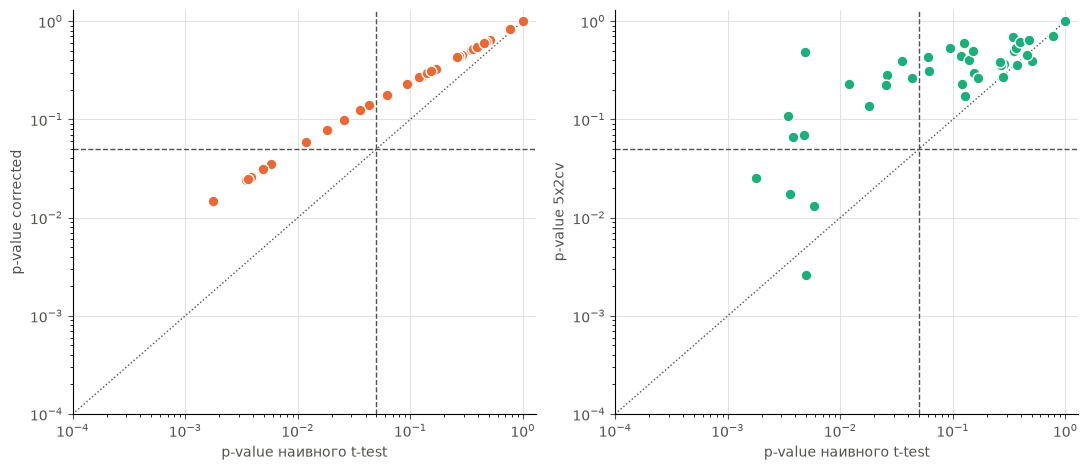

In [16]:
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e3e2de"
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, col, name, color in [(axes[0], "p_corrected", "corrected", "#eb6834"), (axes[1], "p_5x2cv", "5x2cv", "#1baf7a")]:
    ax.scatter(all_pairs.p_naive, all_pairs[col], s=60, color=color, edgecolors="white", linewidths=1, zorder=3)
    ax.plot([1e-4, 1], [1e-4, 1], color=INK2, linewidth=1, linestyle=":", zorder=1)
    ax.axvline(0.05, color=INK2, linewidth=1, linestyle="--", zorder=1)
    ax.axhline(0.05, color=INK2, linewidth=1, linestyle="--", zorder=1)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(1e-4, 1.3); ax.set_ylim(1e-4, 1.3)
    ax.set_xlabel("p-value наивного t-test", color=INK2)
    ax.set_ylabel(f"p-value {name}", color=INK2)
    ax.tick_params(colors=INK2)
    ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig("results/naive_vs_corrected.png", dpi=150)
plt.show()

**Как читать графики.** Каждая точка — одно из 45 сравнений. По горизонтали p-value наивного теста, по вертикали p-value другого теста (слева corrected, справа 5×2cv), обе шкалы логарифмические. Пунктирные линии — порог 0.05, пунктир по диагонали — «p одинаковые». Точки выше диагонали: другой тест дал большее p, чем наивный. Точка левее вертикального порога и выше горизонтального: наивный тест сказал «значимо», а другой тест «уже нет».

**Результат.** Значимыми (p < 0.05) наивный тест называет 20 сравнений из 45, corrected 14, 5×2cv 9, McNemar 7. Corrected p больше наивного во всех 45 случаях, а в 6 случаях (`digits`: RF против LogReg; `vehicle`: HGB против LogReg и RF против HGB; `glass`: HGB против LogReg и RF против HGB; `blood`: RF против LogReg) вывод меняется со «значимо» на «не значимо». Там, где разница огромная (`phoneme`, `segment`, `spambase`), все тесты согласны.

### Доверительные интервалы для разницы точности

p-value отвечает на вопрос «значимо или нет», но не говорит о размере разницы. Доверительный интервал показывает и то и другое: точка — средняя разность точности по 10 фолдам, отрезок — 95% интервал `среднее ± t_крит · SE`. Синий интервал считается с обычной стандартной ошибкой `std/√k`, оранжевый — с поправкой Nadeau & Bengio (дисперсия берётся из `baycomp`). Если интервал накрывает 0, данные совместимы с отсутствием разницы. Показаны все три пары моделей на двух датасетах (`digits` и `credit_g`).

In [17]:
ci_rows = []
for ds in ("digits", "credit_g"):
    for a, b in PAIRS:
        sa, sb = results[ds][a], results[ds][b]
        diff = sa - sb
        n = len(diff)
        mean = diff.mean()
        tcrit = stats.t.ppf(0.975, n - 1)
        se_naive = np.sqrt(np.var(diff, ddof=1) / n)
        _, var_corr, _ = CorrelatedTTest.compute_statistics(sb, sa)
        se_corr = np.sqrt(var_corr)
        ci_rows.append({
            "label": f"{a.upper()} минус {b.upper()}, {ds}", "mean": mean,
            "lo_n": mean - tcrit * se_naive, "hi_n": mean + tcrit * se_naive,
            "lo_c": mean - tcrit * se_corr, "hi_c": mean + tcrit * se_corr,
        })
ci = pd.DataFrame(ci_rows)
ci.round(4)

,label,mean,lo_n,hi_n,lo_c,hi_c
0,"RF минус LOGREG, digits",0.0167,0.0025,0.0309,-0.0039,0.0373
1,"HGB минус LOGREG, digits",0.0111,-0.0006,0.0228,-0.0059,0.0281
2,"RF минус HGB, digits",0.0056,-0.0078,0.0190,-0.0139,0.0251
3,"RF минус LOGREG, credit_g",0.0120,-0.0164,0.0404,-0.0292,0.0532
4,"HGB минус LOGREG, credit_g",0.0040,-0.0262,0.0342,-0.0399,0.0479
5,"RF минус HGB, credit_g",0.0080,-0.0122,0.0282,-0.0213,0.0373


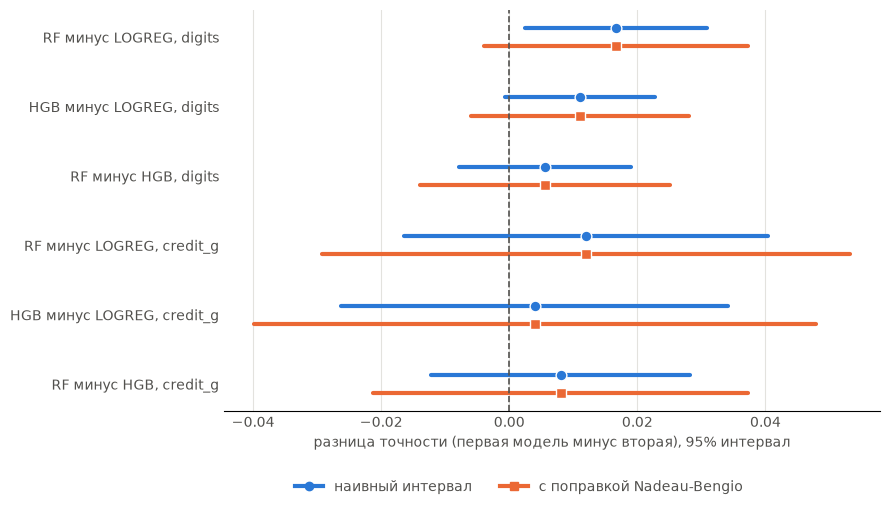

In [18]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(9, 5.2))
ypos = list(range(len(ci)))[::-1]
for y_, (_, r) in zip(ypos, ci.iterrows()):
    ax.plot([r.lo_n, r.hi_n], [y_ + 0.13] * 2, color="#2a78d6", linewidth=3, solid_capstyle="round")
    ax.plot([r.lo_c, r.hi_c], [y_ - 0.13] * 2, color="#eb6834", linewidth=3, solid_capstyle="round")
    ax.scatter([r["mean"]], [y_ + 0.13], color="#2a78d6", s=60, edgecolors="white", zorder=3)
    ax.scatter([r["mean"]], [y_ - 0.13], color="#eb6834", s=60, marker="s", edgecolors="white", zorder=3)
ax.axvline(0, color=INK2, linewidth=1.2, linestyle="--")
ax.set_yticks(ypos); ax.set_yticklabels(ci["label"], color=INK)
ax.set_xlabel("разница точности (первая модель минус вторая), 95% интервал", color=INK2)
ax.tick_params(colors=INK2, length=0)
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.legend(handles=[Line2D([0], [0], color="#2a78d6", lw=3, marker="o", label="наивный интервал"),
                   Line2D([0], [0], color="#eb6834", lw=3, marker="s", label="с поправкой Nadeau-Bengio")],
          loc="upper center", bbox_to_anchor=(0.45, -0.14), ncol=2, frameon=False, labelcolor=INK2)
fig.tight_layout()
fig.savefig("results/confidence_intervals.png", dpi=150)
plt.show()

**Результат.** Наивный интервал не накрывает 0 только у одной пары из шести (RF минус LogReg на `digits`: от 0.0025 до 0.0309). С поправкой этот интервал расширяется до отрезка от −0.0039 до 0.0373 и накрывает 0, как и все остальные. Все средние разности малы (0.4–1.7 п. п.), а интервалы широкие: на этих двух датасетах данных недостаточно, чтобы различить модели.

## Шаг 3 — Групповое сравнение: критерий Фридмана и post-hoc Неменьи

Теперь сравниваем все три модели сразу по всем 15 датасетам. Единицей наблюдения становится датасет, а не фолд: для каждого датасета берётся средняя точность каждой модели (таблица `summary`).

1. **Критерий Фридмана** — непараметрический аналог дисперсионного анализа с повторными измерениями. На каждом датасете модели ранжируются (1 — лучшая), проверяется H0: «средние ранги трёх моделей одинаковы».
2. **Post-hoc Неменьи** запускается, только если H0 Фридмана отвергнута. Он сравнивает пары моделей по разности средних рангов и сам учитывает множественность сравнений. (Здесь H0 не отвергнута, и матрица показана только для полноты.)

Почему не сразу три попарных теста: при нескольких сравнениях растёт вероятность хотя бы одного ложного «значимого» результата. Критерий Фридмана — один общий вопрос «есть ли вообще различие».

In [19]:
stat_friedman, p_friedman = friedmanchisquare(*[summary[m] for m in summary.columns])
print("Friedman:", stat_friedman, p_friedman)

nemenyi_results = sp.posthoc_nemenyi_friedman(summary.values)
nemenyi_results.columns = summary.columns
nemenyi_results.index = summary.columns
nemenyi_results.round(4)

Friedman: 1.3220338983050963 0.5163259901346193


,logreg,rf,hgb
logreg,1.0000,0.5169,0.6896
rf,0.5169,1.0000,0.9595
hgb,0.6896,0.9595,1.0000


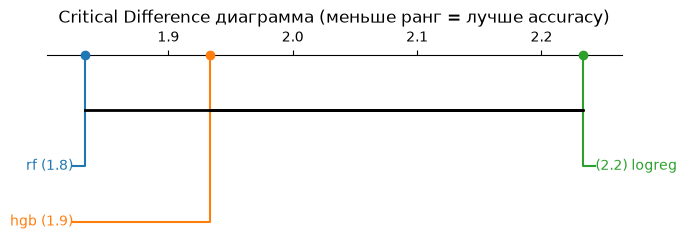

logreg    2.233333
rf        1.833333
hgb       1.933333
dtype: float64

In [20]:
ranks_per_dataset = summary.apply(lambda row: rankdata(-row), axis=1, result_type="expand")
ranks_per_dataset.columns = summary.columns
avg_ranks = ranks_per_dataset.mean(axis=0)

fig, ax = plt.subplots(figsize=(7, 2.5))
sp.critical_difference_diagram(avg_ranks, nemenyi_results, ax=ax)
plt.title("Critical Difference диаграмма (меньше ранг = лучше accuracy)")
plt.tight_layout()
plt.show()
avg_ranks

**Как читать диаграмму критических различий.** По горизонтали — средний ранг (чем меньше, тем лучше по точности). Модели, соединённые горизонтальной перемычкой, статистически неразличимы.

**Результат.** Критерий Фридмана: статистика 1.32, p = 0.52 — оснований считать, что модели различаются, нет. Средние ранги: `rf` 1.83, `hgb` 1.93, `logreg` 2.23; по Неменьи все попарные p от 0.52 до 0.96, на диаграмме все три модели соединены одной перемычкой. Критическая разность рангов для 3 моделей и 15 датасетов около 0.86, а самая большая наблюдаемая разность 0.4. Вывод: **на 15 датасетах нет доказательств, что какая-то из трёх моделей в целом лучше**. Это важное отличие от первой версии работы: там логистическая регрессия выглядела худшей только потому, что на нестандартизованных признаках не сходилась.

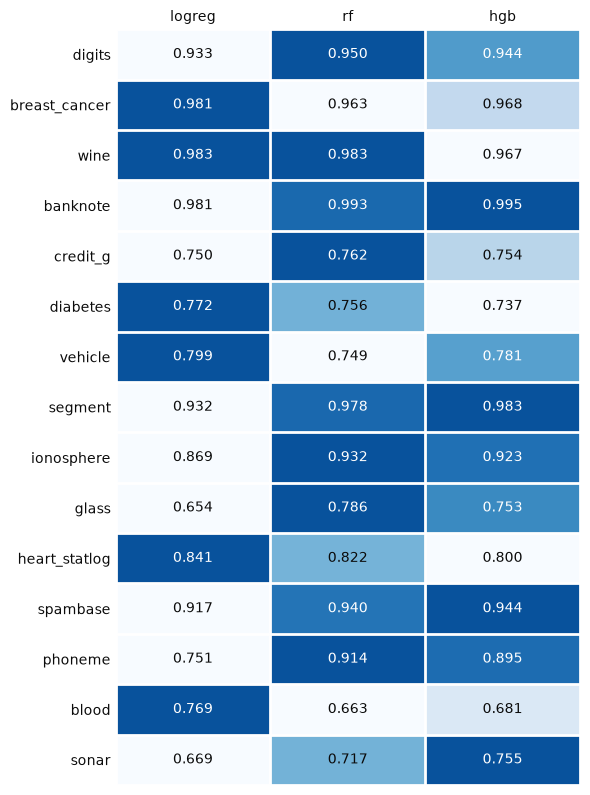

In [21]:
row_scaled = summary.sub(summary.min(axis=1), axis=0).div(summary.max(axis=1) - summary.min(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(6, 0.45 * len(summary) + 1.3))
ax.imshow(row_scaled.values, cmap="Blues", vmin=0, vmax=1.15, aspect="auto")
for i in range(summary.shape[0]):
    for j in range(summary.shape[1]):
        ax.text(j, i, f"{summary.iloc[i, j]:.3f}", ha="center", va="center", fontsize=10,
                color="white" if row_scaled.iloc[i, j] > 0.6 else INK)
ax.set_xticks(range(summary.shape[1])); ax.set_xticklabels(summary.columns, color=INK)
ax.set_yticks(range(summary.shape[0])); ax.set_yticklabels(summary.index, color=INK)
ax.xaxis.tick_top(); ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks(np.arange(-.5, summary.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, summary.shape[0], 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2); ax.tick_params(which="minor", length=0)
fig.tight_layout()
fig.savefig("results/summary_heatmap.png", dpi=150)
plt.show()

## Шаг 4 — Поправка Холма на множественные сравнения

Каждый из четырёх тестов проверяет 45 гипотез. Если к каждой применять порог 0.05, то даже без реальных различий в среднем 45 × 0.05 ≈ 2 сравнения окажутся «значимыми» случайно. Метод Холма пересчитывает p-value так, чтобы вероятность хотя бы одной ложной находки среди всех 45 проверок не превышала 0.05. Поправка применяется к каждому тесту отдельно.

In [22]:
holm_rows = []
for t in TESTS:
    reject, p_adj, _, _ = multipletests(all_pairs[t], alpha=0.05, method="holm")
    all_pairs[t + "_holm"] = p_adj
    holm_rows.append({"тест": t, "значимо до поправки": int((all_pairs[t] < 0.05).sum()), "значимо после Холма": int(reject.sum())})
holm_table = pd.DataFrame(holm_rows).set_index("тест")
for t in TESTS:
    surv = all_pairs[all_pairs[t + "_holm"] < 0.05]
    print(t, "->", list(zip(surv.dataset, surv.pair)))
holm_table

p_naive -> [('segment', 'rf vs logreg'), ('segment', 'hgb vs logreg'), ('spambase', 'hgb vs logreg'), ('phoneme', 'rf vs logreg'), ('phoneme', 'hgb vs logreg'), ('phoneme', 'rf vs hgb')]
p_corrected -> [('segment', 'rf vs logreg'), ('segment', 'hgb vs logreg'), ('spambase', 'hgb vs logreg'), ('phoneme', 'rf vs logreg'), ('phoneme', 'hgb vs logreg'), ('phoneme', 'rf vs hgb')]
p_5x2cv -> [('segment', 'hgb vs logreg'), ('phoneme', 'rf vs logreg'), ('phoneme', 'hgb vs logreg')]
p_mcnemar -> [('segment', 'rf vs logreg'), ('segment', 'hgb vs logreg'), ('spambase', 'rf vs logreg'), ('spambase', 'hgb vs logreg'), ('phoneme', 'rf vs logreg'), ('phoneme', 'hgb vs logreg')]


,значимо до поправки,значимо после Холма
тест,,
p_naive,20,6
p_corrected,14,6
p_5x2cv,9,3
p_mcnemar,7,6


**Интерпретация.** До поправки значимыми (p < 0.05) были: наивный 20, corrected 14, 5×2cv 9, McNemar 7 сравнений из 45. После поправки Холма остаётся: наивный 6, corrected 6, 5×2cv 3, McNemar 6. У наивного и corrected тестов это одни и те же шесть сравнений: `segment` (RF и HGB против LogReg), `spambase` (HGB против LogReg) и все три пары на `phoneme`. Остальные «находки» могли получиться случайно из-за большого числа проверок. Важно: после Холма наивный и corrected тесты совпадают, а расходились они только на пограничных результатах.

## Шаг 5 — Симуляция: насколько на самом деле ошибается каждый тест

Таблицы выше не отвечают на вопрос, какой тест «прав»: истинной разницы между реальными моделями мы не знаем. Поэтому ставим контролируемый эксперимент с известным ответом.

**Данные.** Каждый раз генерируется новый набор объектов с двумя классами; у каждого объекта два независимых «вида» по 5 признаков (класс сдвигает среднее признака на ±shift, остальное — шум). Модель A (логистическая регрессия) видит только первый вид, модель B — только второй.
- **Сценарий H0:** сдвиг одинаков (0.45) в обоих видах, по симметрии ожидаемая точность моделей **одинакова**, H0 верна. Доля случаев, когда тест на уровне 0.05 всё же говорит «значимо», — это **ошибка первого рода** (должна быть около 5%).
- **Сценарий H1:** во втором виде сдвиг меньше (0.30), модель B объективно хуже. Доля «значимых» результатов — это **мощность** теста.

**Пять процедур:** наивный t-test на 10-fold; он же с поправкой Nadeau & Bengio; 5×2cv; наивный t-test на 30 повторных случайных разбиениях (2/3 обучение, 1/3 проверка); он же с поправкой (`1/30 + 1/2`). Повторные случайные разбиения — именно тот сценарий, для которого Nadeau & Bengio придумали поправку.

Каждый сценарий — 500 независимых повторов; размер выборки меняется (100, 200 и 400 объектов), чтобы проверить, что вывод не зависит от размера.

In [23]:
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedKFold, ShuffleSplit

D = 5
N_REPS = 500
K, J = 10, 30
METHODS = ["наивный, 10-fold", "corrected, 10-fold", "5x2cv", "наивный, 30 разбиений", "corrected, 30 разбиений"]


def make_two_view_data(rng, n_objects, shift1, shift2):
    y = rng.randint(0, 2, n_objects)
    sign = (2 * y - 1)[:, None]
    view1 = sign * shift1 + rng.randn(n_objects, D)
    view2 = sign * shift2 + rng.randn(n_objects, D)
    return np.hstack([view1, view2]), y


def p_from_differences(d, variance_factor, df):
    sd = d.std(ddof=1)
    if sd == 0:
        return np.nan
    t = d.mean() / (sd * np.sqrt(variance_factor))
    return 2 * stats.t.sf(abs(t), df)


def one_repetition(rep, n_objects, shift2):
    rng = np.random.RandomState(rep)
    X, y = make_two_view_data(rng, n_objects, 0.45, shift2)
    make_model = lambda cols: make_pipeline(
        ColumnTransformer([("select", "passthrough", cols)]), LogisticRegression())
    model_a, model_b = make_model(list(range(D))), make_model(list(range(D, 2 * D)))

    cv = StratifiedKFold(n_splits=K, shuffle=True, random_state=rep)
    d = cross_val_score(model_a, X, y, cv=cv) - cross_val_score(model_b, X, y, cv=cv)
    p_naive_kfold = p_from_differences(d, 1 / K, K - 1)
    p_corr_kfold = p_from_differences(d, 1 / K + 1 / (K - 1), K - 1)
    _, p_5x2 = paired_ttest_5x2cv(model_a, model_b, X, y, random_seed=rep)

    resampling = ShuffleSplit(n_splits=J, test_size=1 / 3, random_state=rep)
    d2 = cross_val_score(model_a, X, y, cv=resampling) - cross_val_score(model_b, X, y, cv=resampling)
    p_naive_res = p_from_differences(d2, 1 / J, J - 1)
    p_corr_res = p_from_differences(d2, 1 / J + 1 / 2, J - 1)   # n_test / n_train = (1/3) / (2/3) = 1/2
    return [p_naive_kfold, p_corr_kfold, p_5x2, p_naive_res, p_corr_res]


sim_tables = {}
for n_objects in (100, 200, 400):
    rates = {}
    for scenario, shift2 in [("H0: модели равны", 0.45), ("H1: модель B хуже", 0.30)]:
        p_array = np.array(Parallel(n_jobs=-1)(delayed(one_repetition)(r, n_objects, shift2) for r in range(N_REPS)))
        p_array = p_array[~np.isnan(p_array).any(axis=1)]
        rates[scenario] = (p_array < 0.05).mean(axis=0)
    sim_tables[n_objects] = pd.DataFrame(rates, index=METHODS)

sim_table = sim_tables[200]
sim_table.round(3)

,H0: модели равны,H1: модель B хуже
"наивный, 10-fold",0.030,0.534
"corrected, 10-fold",0.008,0.254
5x2cv,0.040,0.372
"наивный, 30 разбиений",0.588,0.974
"corrected, 30 разбиений",0.038,0.570


In [24]:
pd.concat({n: t["H0: модели равны"] for n, t in sim_tables.items()}, axis=1).round(3)

,100,200,400
"наивный, 10-fold",0.050,0.030,0.066
"corrected, 10-fold",0.010,0.008,0.016
5x2cv,0.084,0.040,0.046
"наивный, 30 разбиений",0.586,0.588,0.594
"corrected, 30 разбиений",0.028,0.038,0.048


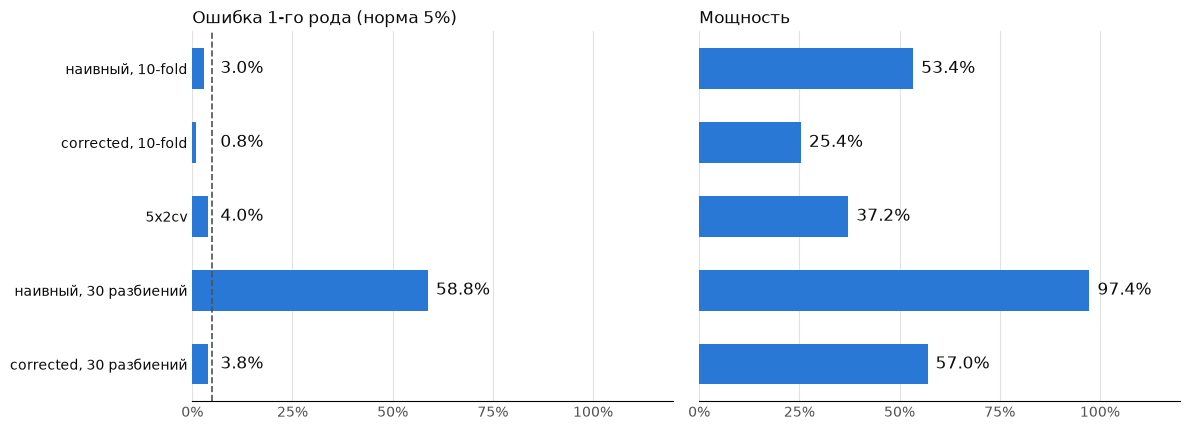

In [25]:
from matplotlib.ticker import PercentFormatter

panels = [("H0: модели равны", "Ошибка 1-го рода (норма 5%)"), ("H1: модель B хуже", "Мощность")]
ypos = np.arange(len(METHODS))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, (scenario, title) in zip(axes, panels):
    values = sim_table[scenario].values
    ax.barh(ypos, values, height=0.55, color="#2a78d6")
    for y_, v in zip(ypos, values):
        ax.text(max(v, 0.05) + 0.02, y_, f"{v:.1%}", va="center", color=INK, fontsize=12)
    ax.set_xlim(0, 1.2)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_title(title, color=INK, loc="left")
    ax.tick_params(colors=INK2, length=0)
    ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
axes[0].axvline(0.05, color=INK2, linewidth=1.2, linestyle="--")
axes[0].set_yticks(ypos); axes[0].set_yticklabels(METHODS, color=INK)
fig.tight_layout()
fig.savefig("results/simulation_size_power.png", dpi=150)
plt.show()

**Результаты симуляции** (200 объектов, 500 повторов на сценарий):

| процедура | ошибка 1-го рода (H0) | мощность (H1) |
|---|---|---|
| наивный, 10-fold | 3.0% | 53.4% |
| corrected, 10-fold | 0.8% | 25.4% |
| 5×2cv | 4.0% | 37.2% |
| наивный, 30 разбиений | **58.8%** | 97.4% |
| corrected, 30 разбиений | 3.8% | 57.0% |

Таблица под графиком показывает ошибку первого рода при 100, 200 и 400 объектах: картина одна и та же (наивный на 30 разбиениях около 59% при любом размере выборки, наивный на 10-fold от 3% до 7%, corrected на 10-fold от 0.8% до 1.6%).

**Что это значит.**
1. Катастрофически неверен наивный t-test на **повторных случайных разбиениях**: он «находит» разницу между заведомо равными моделями в 59% случаев вместо 5%. Здесь пересечение выборок максимально, допущение независимости разрушено полностью. Простая математика это подтверждает: при корреляции результатов около 1/3 дисперсия среднего у 30 значений в 1 + 29/3 ≈ 10.7 раза больше, чем считает наивный тест, и ожидаемая доля ложных находок около 50%. Поправка Nadeau & Bengio возвращает ошибку к номиналу (3.8%).
2. Наивный t-test на **10-fold** в этом дизайне ошибку первого рода почти не завышает (3–7%). Допущение независимости формально нарушено, но практический эффект здесь небольшой.
3. Поправка Nadeau & Bengio, применённая к 10-fold, **излишне консервативна**: ошибка 0.8–1.6% (ниже номинала), мощность падает с 53% до 25%. Корреляция между фолдами здесь практически нулевая, а поправка закладывает заметную. Если истинная корреляция нулевая, ожидаемая доля ложных находок у corrected теста около 1%, что и наблюдается.
4. 5×2cv держит ошибку около номинала (4–8%) при умеренной мощности (37%).

**Ограничение:** это один дизайн (логистическая регрессия, гауссовы признаки); количественные значения на других моделях и данных будут иными.

## Выводы

1. **Выбор теста меняет результат.** Из 45 сравнений наивный тест находит значимую разницу в 20, corrected в 14, 5×2cv в 9, McNemar в 7. Поправка Nadeau & Bengio увеличивает p во всех 45 случаях и переводит 6 сравнений из «значимых» в «незначимые».
2. **Сильные различия видны всем тестам.** После поправки Холма и наивный, и corrected тесты оставляют одни и те же 6 сравнений (`segment`, `spambase`, `phoneme`), где разрыв между моделями от 2 до 16 п. п. Расхождения между тестами касаются пограничных результатов (p от 0.01 до 0.05).
3. **Симуляция показала, где именно проблема.** Наивный t-test на повторных случайных разбиениях ошибается в 59% случаев при номинальных 5%; на 10-fold он близок к номиналу (3–7%). Поправка Nadeau & Bengio исправляет повторные разбиения (3.8%), но на 10-fold излишне консервативна (0.8–1.6%, мощность 25% против 53%). Тезис «наивный t-test на фолдах CV некорректен» верен как утверждение о нарушенных допущениях, но его практическая тяжесть зависит от схемы разбиения.
4. **Групповое сравнение.** Критерий Фридмана на 15 датасетах незначим (p = 0.52): доказательств, что одна из трёх моделей в целом лучше, нет. Средние ранги почти равны (RF 1.83, HGB 1.93, LogReg 2.23).
5. **Размер эффекта.** Разрывы между моделями от долей процента до 16 п. п.; там, где они малы (1–2 п. п.), даже corrected интервалы накрывают 0.

## Ограничения

- 15 датасетов — на уровне классических работ по сравнению классификаторов (14–30), но мощность группового теста всё равно ограничена; все датасеты — табличные задачи классификации небольшого размера.
- Гиперпараметры по умолчанию, без тюнинга: это осознанный выбор, потому что цель работы — тесты, а не точность. Подбор параметров потребовал бы вложенной кросс-валидации.
- На реальных данных истинная разница между моделями неизвестна, поэтому можно судить о согласованности тестов, но не о том, какой из них «прав»; для этого и нужна симуляция.
- Симуляция — один дизайн (логистическая регрессия, гауссовы признаки, 500 повторов; размер выборки 100, 200 и 400); количественные значения на других моделях будут иными.
- 5×2cv и McNemar зависят от случайного разбиения; в таблице по 45 сравнениям приведена медиана p по 5 и 10 разбиениям.
- Датасет `glass` содержит класс из 9 объектов, меньше числа фолдов: стратификация 10-fold на нём неидеальна.